In [1]:
import json

FILTER_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset_3/x_ray/filter_decisions.jsonl"

records = [json.loads(l) for l in open(FILTER_FILE)]

texts, labels = [], []
for rec in records:
    q = rec["question"].replace("<image>", "").strip()
    texts.append(q)
    labels.append(rec["decision"])  # "KEEP" or "REMOVE"

from collections import Counter
print(Counter(labels))
print("Total:", len(texts))
print("\nExample KEEP:", next(t for t, l in zip(texts, labels) if l == "KEEP"))
print("Example REMOVE:", next(t for t, l in zip(texts, labels) if l == "REMOVE"))


Counter({'REMOVE': 18728, 'KEEP': 2158})
Total: 20886

Example KEEP: Are there any other findings in the image?
Example REMOVE: What is the age and gender of the patient?


In [2]:
import torch
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
from torch.optim import AdamW

LABEL2ID = {"KEEP": 1, "REMOVE": 0}

X_train, X_val, y_train, y_val = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

class QDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(texts, truncation=True, padding=True, max_length=64)
        self.labels = [LABEL2ID[l] for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return {
            "input_ids":      torch.tensor(self.enc["input_ids"][i]),
            "attention_mask": torch.tensor(self.enc["attention_mask"][i]),
            "labels":         torch.tensor(self.labels[i]),
        }

train_ds = QDataset(X_train, y_train)
val_ds   = QDataset(X_val,   y_val)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)

# class weights to handle imbalance
n_remove = y_train.count("REMOVE")
n_keep   = y_train.count("KEEP")
weights  = torch.tensor([1.0, n_remove / n_keep]).cuda()

model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
model = model.cuda()
optimizer = AdamW(model.parameters(), lr=2e-5)

for epoch in range(3):
    model.train()
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
            labels=batch["labels"].cuda(),
        )
        loss = torch.nn.functional.cross_entropy(out.logits, batch["labels"].cuda(), weight=weights)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}  loss={total_loss/len(train_loader):.4f}")

# Evaluate
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        # preds = out.logits.argmax(dim=-1).cpu().tolist()
        prob_keep = torch.softmax(out.logits, dim=-1)[:, 1]
        pred = (prob_keep >= 0.83).int()  # 1=KEEP, 0=REMOVE
        all_preds.extend(pred.tolist())
        all_true.extend(batch["labels"].tolist())

print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))


/home/as5606/miniconda3/envs/biomedclip/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 16708  Val: 4178


Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:02<00:00, 45.31it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1  loss=0.2970
Epoch 2  loss=0.1418
Epoch 3  loss=0.0931
              precision    recall  f1-score   support

      REMOVE       0.98      0.99      0.98      3746
        KEEP       0.89      0.84      0.86       432

    accuracy                           0.97      4178
   macro avg       0.93      0.91      0.92      4178
weighted avg       0.97      0.97      0.97      4178



In [3]:
# Evaluate
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        # preds = out.logits.argmax(dim=-1).cpu().tolist()
        prob_keep = torch.softmax(out.logits, dim=-1)[:, 1]
        pred = (prob_keep >= 0.83).int()  # 1=KEEP, 0=REMOVE
        all_preds.extend(pred.tolist())
        all_true.extend(batch["labels"].tolist())

print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))

              precision    recall  f1-score   support

      REMOVE       0.98      0.99      0.98      3746
        KEEP       0.89      0.84      0.86       432

    accuracy                           0.97      4178
   macro avg       0.93      0.91      0.92      4178
weighted avg       0.97      0.97      0.97      4178



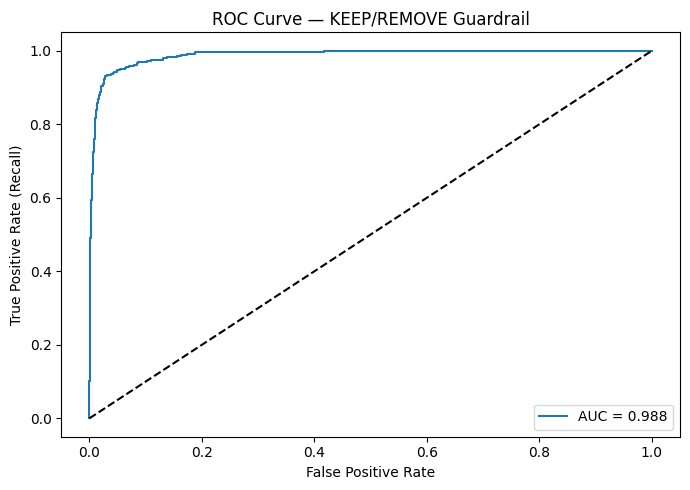

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

model.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist()  # prob of KEEP
        all_probs.extend(probs)
        all_true.extend(batch["labels"].tolist())

fpr, tpr, thresholds = roc_curve(all_true, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — KEEP/REMOVE Guardrail")
plt.legend()
plt.tight_layout()
plt.show()


Best threshold : 0.7769
KEEP precision : 0.868
KEEP recall    : 0.868
KEEP F1        : 0.868


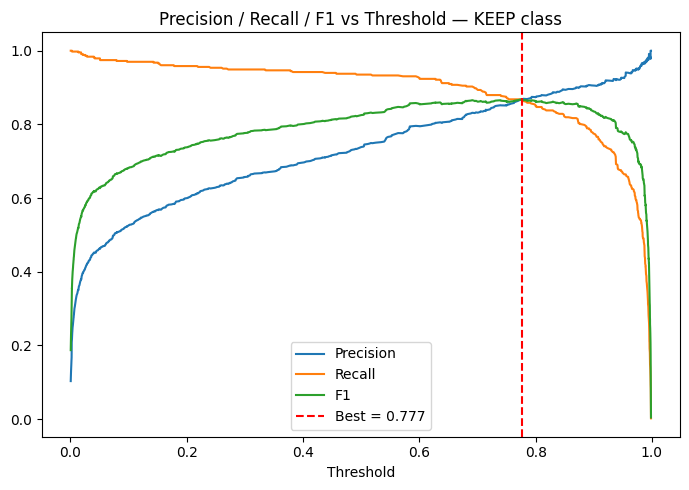

In [5]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(all_true, all_probs)

# F1 for KEEP at each threshold
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = f1_scores.argmax()

print(f"Best threshold : {thresholds[best_idx]:.4f}")
print(f"KEEP precision : {precision[best_idx]:.3f}")
print(f"KEEP recall    : {recall[best_idx]:.3f}")
print(f"KEEP F1        : {f1_scores[best_idx]:.3f}")

plt.figure(figsize=(7, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores[:-1], label="F1")
plt.axvline(thresholds[best_idx], color="red", linestyle="--", label=f"Best = {thresholds[best_idx]:.3f}")
plt.xlabel("Threshold")
plt.title("Precision / Recall / F1 vs Threshold — KEEP class")
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
import os

SAVE_DIR = "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_xray"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

# save the threshold too
import json
json.dump({"threshold": 0.83}, open(f"{SAVE_DIR}/config.json", "w"))

print(f"Saved to {SAVE_DIR}")


Writing model shards: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.25s/it]

Saved to /home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_xray


Pathology

In [7]:
FILTER_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset_3/gross_pathology/filter_decisions.jsonl"

records = [json.loads(l) for l in open(FILTER_FILE)]

texts, labels = [], []
for rec in records:
    q = rec["question"].replace("<image>", "").strip()
    texts.append(q)
    labels.append(rec["decision"])

from collections import Counter
print(Counter(labels))
print("Total:", len(texts))


Counter({'REMOVE': 6177, 'KEEP': 844})
Total: 7021


In [8]:
n_remove = y_train.count("REMOVE")
n_keep   = y_train.count("KEEP")
weights  = torch.tensor([1.0, n_remove / n_keep]).cuda()

X_train, X_val, y_train, y_val = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

tokenizer_gp = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

train_ds = QDataset(X_train, y_train)
val_ds   = QDataset(X_val,   y_val)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)

model_gp = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
model_gp = model_gp.cuda()
optimizer = AdamW(model_gp.parameters(), lr=2e-5)

for epoch in range(3):
    model_gp.train()
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model_gp(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        loss = torch.nn.functional.cross_entropy(out.logits, batch["labels"].cuda(), weight=weights)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}  loss={total_loss/len(train_loader):.4f}")

model_gp.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model_gp(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist()
        all_probs.extend(probs)
        all_true.extend(batch["labels"].tolist())

# find best threshold
from sklearn.metrics import precision_recall_curve
precision, recall, thresholds = precision_recall_curve(all_true, all_probs)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = f1_scores.argmax()
best_thresh = thresholds[best_idx]
print(f"Best threshold: {best_thresh:.4f}  P={precision[best_idx]:.3f}  R={recall[best_idx]:.3f}  F1={f1_scores[best_idx]:.3f}")

all_preds = (np.array(all_probs) >= best_thresh).astype(int).tolist()
print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))


Train: 5616  Val: 1405


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 10021.51it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1  loss=0.4642
Epoch 2  loss=0.2323
Epoch 3  loss=0.1542
Best threshold: 0.7931  P=0.630  R=0.805  F1=0.706
              precision    recall  f1-score   support

      REMOVE       0.97      0.94      0.95      1236
        KEEP       0.63      0.80      0.71       169

    accuracy                           0.92      1405
   macro avg       0.80      0.87      0.83      1405
weighted avg       0.93      0.92      0.92      1405



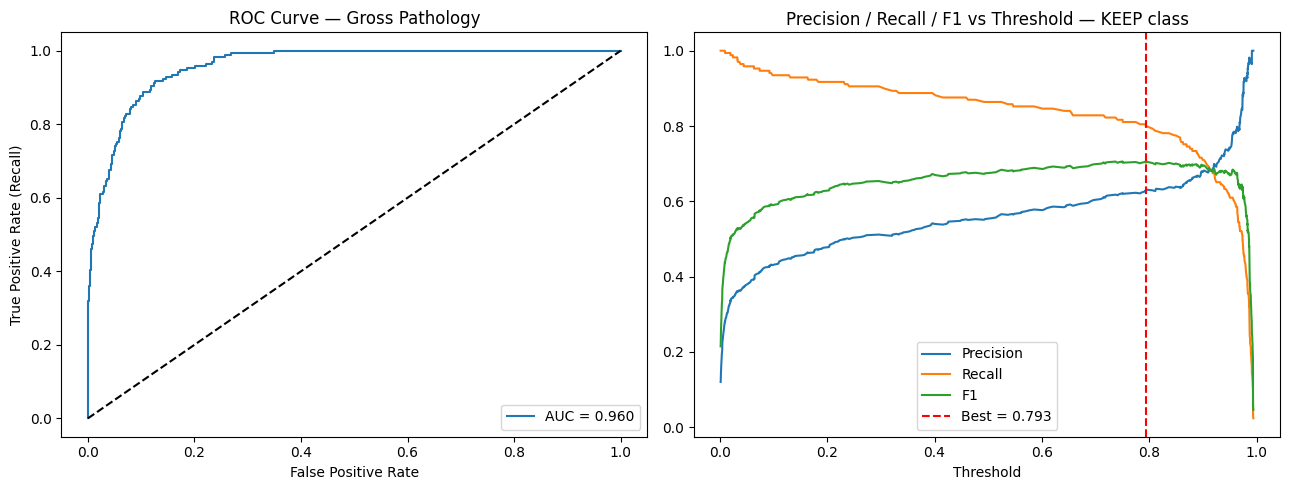


Best threshold: 0.7931  P=0.630  R=0.805  F1=0.706
              precision    recall  f1-score   support

      REMOVE       0.97      0.94      0.95      1236
        KEEP       0.63      0.80      0.71       169

    accuracy                           0.92      1405
   macro avg       0.80      0.87      0.83      1405
weighted avg       0.93      0.92      0.92      1405



In [9]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

# ROC curve
fpr, tpr, _ = roc_curve(all_true, all_probs)
roc_auc = auc(fpr, tpr)

# Precision-Recall curve + best threshold
precision, recall, thresholds = precision_recall_curve(all_true, all_probs)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = f1_scores.argmax()
best_thresh = thresholds[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: ROC
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC Curve — Gross Pathology")
axes[0].legend()

# Right: P/R/F1 vs threshold
axes[1].plot(thresholds, precision[:-1], label="Precision")
axes[1].plot(thresholds, recall[:-1], label="Recall")
axes[1].plot(thresholds, f1_scores[:-1], label="F1")
axes[1].axvline(best_thresh, color="red", linestyle="--", label=f"Best = {best_thresh:.3f}")
axes[1].set_xlabel("Threshold")
axes[1].set_title("Precision / Recall / F1 vs Threshold — KEEP class")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nBest threshold: {best_thresh:.4f}  P={precision[best_idx]:.3f}  R={recall[best_idx]:.3f}  F1={f1_scores[best_idx]:.3f}")

all_preds = (np.array(all_probs) >= best_thresh).astype(int).tolist()
print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))


In [10]:
SAVE_DIR = "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_gross_pathology"
os.makedirs(SAVE_DIR, exist_ok=True)

model_gp.save_pretrained(SAVE_DIR)
tokenizer_gp.save_pretrained(SAVE_DIR)

json.dump({"threshold": round(best_thresh, 4)}, open(f"{SAVE_DIR}/config.json", "w"))

print(f"Saved to {SAVE_DIR}")


Writing model shards:   0%|                                                                                                                       | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.56it/s]

Saved to /home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_gross_pathology


## CT


In [11]:
FILTER_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset_3/CT/filter_decisions.jsonl"

records = [json.loads(l) for l in open(FILTER_FILE)]

texts, labels = [], []
for rec in records:
    q = rec["question"].replace("<image>", "").strip()
    texts.append(q)
    labels.append(rec["decision"])

print(Counter(labels))
print("Total:", len(texts))


Counter({'REMOVE': 38830, 'KEEP': 8738})
Total: 47568


Train: 38054  Val: 9514


Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:01<00:00, 66.70it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1  loss=0.1965
Epoch 2  loss=0.1116
Epoch 3  loss=0.0811


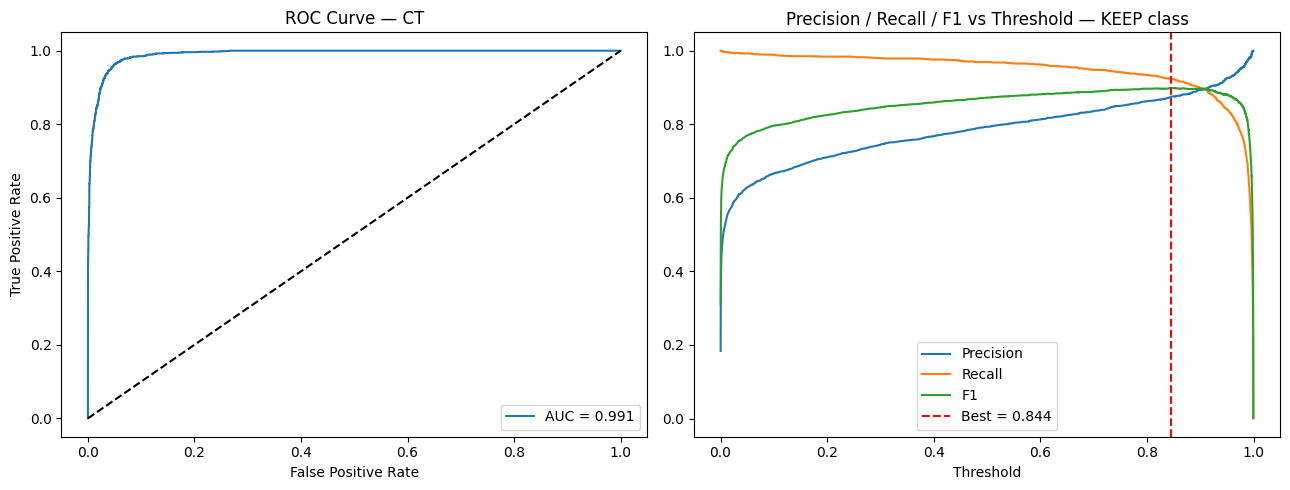


Best threshold: 0.8440  P=0.875  R=0.924  F1=0.899
              precision    recall  f1-score   support

      REMOVE       0.98      0.97      0.98      7766
        KEEP       0.87      0.92      0.90      1748

    accuracy                           0.96      9514
   macro avg       0.93      0.95      0.94      9514
weighted avg       0.96      0.96      0.96      9514



In [12]:
X_train, X_val, y_train, y_val = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

n_remove = y_train.count("REMOVE")
n_keep   = y_train.count("KEEP")
weights  = torch.tensor([1.0, n_remove / n_keep]).cuda()

tokenizer_ct = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

train_ds = QDataset(X_train, y_train)
val_ds   = QDataset(X_val,   y_val)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)

model_ct = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
model_ct = model_ct.cuda()
optimizer = AdamW(model_ct.parameters(), lr=2e-5)

for epoch in range(3):
    model_ct.train()
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model_ct(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        loss = torch.nn.functional.cross_entropy(out.logits, batch["labels"].cuda(), weight=weights)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}  loss={total_loss/len(train_loader):.4f}")

model_ct.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model_ct(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist()
        all_probs.extend(probs)
        all_true.extend(batch["labels"].tolist())

fpr, tpr, _ = roc_curve(all_true, all_probs)
roc_auc = auc(fpr, tpr)

precision, recall, thresholds = precision_recall_curve(all_true, all_probs)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = f1_scores.argmax()
best_thresh = thresholds[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve — CT")
axes[0].legend()

axes[1].plot(thresholds, precision[:-1], label="Precision")
axes[1].plot(thresholds, recall[:-1], label="Recall")
axes[1].plot(thresholds, f1_scores[:-1], label="F1")
axes[1].axvline(best_thresh, color="red", linestyle="--", label=f"Best = {best_thresh:.3f}")
axes[1].set_xlabel("Threshold")
axes[1].set_title("Precision / Recall / F1 vs Threshold — KEEP class")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nBest threshold: {best_thresh:.4f}  P={precision[best_idx]:.3f}  R={recall[best_idx]:.3f}  F1={f1_scores[best_idx]:.3f}")
all_preds = (np.array(all_probs) >= best_thresh).astype(int).tolist()
print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))


In [13]:
SAVE_DIR = "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_ct"
os.makedirs(SAVE_DIR, exist_ok=True)

model_ct.save_pretrained(SAVE_DIR)
tokenizer_ct.save_pretrained(SAVE_DIR)

json.dump({"threshold": round(best_thresh, 4)}, open(f"{SAVE_DIR}/config.json", "w"))

print(f"Saved to {SAVE_DIR}")


Writing model shards:   0%|                                                                                                                       | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.53it/s]

Saved to /home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_ct


## Histology

In [14]:
FILTER_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset_3/histology/filter_decisions.jsonl"

records = [json.loads(l) for l in open(FILTER_FILE)]

texts, labels = [], []
for rec in records:
    q = rec["question"].replace("<image>", "").strip()
    texts.append(q)
    labels.append(rec["decision"])

print(Counter(labels))
print("Total:", len(texts))


Counter({'REMOVE': 39658, 'KEEP': 7418})
Total: 47076


Train: 37660  Val: 9416


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:00<00:00, 6867.46it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1  loss=0.2632
Epoch 2  loss=0.1533
Epoch 3  loss=0.1117


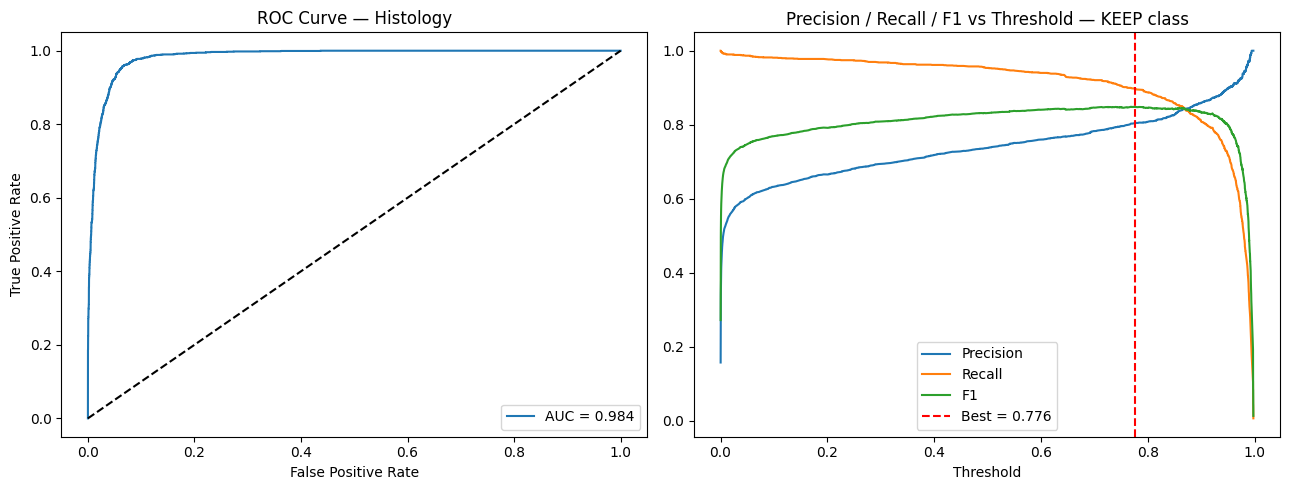


Best threshold: 0.7765  P=0.805  R=0.898  F1=0.849
              precision    recall  f1-score   support

      REMOVE       0.98      0.96      0.97      7932
        KEEP       0.81      0.90      0.85      1484

    accuracy                           0.95      9416
   macro avg       0.89      0.93      0.91      9416
weighted avg       0.95      0.95      0.95      9416



In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

n_remove = y_train.count("REMOVE")
n_keep   = y_train.count("KEEP")
weights  = torch.tensor([1.0, n_remove / n_keep]).cuda()

tokenizer_hist = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

train_ds = QDataset(X_train, y_train)
val_ds   = QDataset(X_val,   y_val)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)

model_hist = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
model_hist = model_hist.cuda()
optimizer = AdamW(model_hist.parameters(), lr=2e-5)

for epoch in range(3):
    model_hist.train()
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model_hist(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        loss = torch.nn.functional.cross_entropy(out.logits, batch["labels"].cuda(), weight=weights)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}  loss={total_loss/len(train_loader):.4f}")

model_hist.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model_hist(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist()
        all_probs.extend(probs)
        all_true.extend(batch["labels"].tolist())

fpr, tpr, _ = roc_curve(all_true, all_probs)
roc_auc = auc(fpr, tpr)

precision, recall, thresholds = precision_recall_curve(all_true, all_probs)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = f1_scores.argmax()
best_thresh = thresholds[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve — Histology")
axes[0].legend()

axes[1].plot(thresholds, precision[:-1], label="Precision")
axes[1].plot(thresholds, recall[:-1], label="Recall")
axes[1].plot(thresholds, f1_scores[:-1], label="F1")
axes[1].axvline(best_thresh, color="red", linestyle="--", label=f"Best = {best_thresh:.3f}")
axes[1].set_xlabel("Threshold")
axes[1].set_title("Precision / Recall / F1 vs Threshold — KEEP class")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nBest threshold: {best_thresh:.4f}  P={precision[best_idx]:.3f}  R={recall[best_idx]:.3f}  F1={f1_scores[best_idx]:.3f}")
all_preds = (np.array(all_probs) >= best_thresh).astype(int).tolist()
print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))


In [16]:
SAVE_DIR = "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_histology"
os.makedirs(SAVE_DIR, exist_ok=True)

model_hist.save_pretrained(SAVE_DIR)
tokenizer_hist.save_pretrained(SAVE_DIR)

json.dump({"threshold": round(best_thresh, 4)}, open(f"{SAVE_DIR}/config.json", "w"))

print(f"Saved to {SAVE_DIR}")


Writing model shards: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.08it/s]

Saved to /home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_histology


## MRI

In [18]:
FILTER_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset_3/MRI/filter_decisions.jsonl"

records = [json.loads(l) for l in open(FILTER_FILE)]

texts, labels = [], []
for rec in records:
    q = rec["question"].replace("<image>", "").strip()
    texts.append(q)
    labels.append(rec["decision"])

print(Counter(labels))
print("Total:", len(texts))


Counter({'REMOVE': 38303, 'KEEP': 7178})
Total: 45481


Train: 36384  Val: 9097


Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:01<00:00, 51.01it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1  loss=0.2957
Epoch 2  loss=0.1834
Epoch 3  loss=0.1355


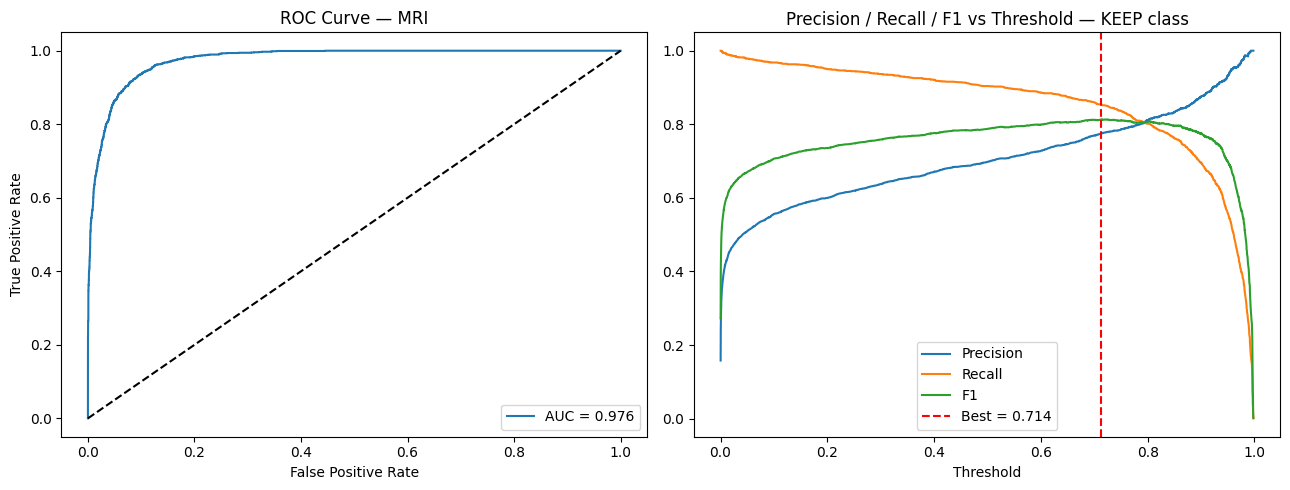


Best threshold: 0.7135  P=0.776  R=0.854  F1=0.813
              precision    recall  f1-score   support

      REMOVE       0.97      0.95      0.96      7661
        KEEP       0.78      0.85      0.81      1436

    accuracy                           0.94      9097
   macro avg       0.87      0.90      0.89      9097
weighted avg       0.94      0.94      0.94      9097



In [19]:
X_train, X_val, y_train, y_val = train_test_split(
    [t for t, l in zip(texts, labels) if l in ("KEEP", "REMOVE")],
    [l for l in labels if l in ("KEEP", "REMOVE")],
    test_size=0.2, random_state=42, stratify=[l for l in labels if l in ("KEEP", "REMOVE")]
)
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

n_remove = y_train.count("REMOVE")
n_keep   = y_train.count("KEEP")
weights  = torch.tensor([1.0, n_remove / n_keep]).cuda()

tokenizer_mri = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

train_ds = QDataset(X_train, y_train)
val_ds   = QDataset(X_val,   y_val)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)

model_mri = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
model_mri = model_mri.cuda()
optimizer = AdamW(model_mri.parameters(), lr=2e-5)

for epoch in range(3):
    model_mri.train()
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model_mri(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        loss = torch.nn.functional.cross_entropy(out.logits, batch["labels"].cuda(), weight=weights)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}  loss={total_loss/len(train_loader):.4f}")

model_mri.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model_mri(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist()
        all_probs.extend(probs)
        all_true.extend(batch["labels"].tolist())

fpr, tpr, _ = roc_curve(all_true, all_probs)
roc_auc = auc(fpr, tpr)

precision, recall, thresholds = precision_recall_curve(all_true, all_probs)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = f1_scores.argmax()
best_thresh = thresholds[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve — MRI")
axes[0].legend()

axes[1].plot(thresholds, precision[:-1], label="Precision")
axes[1].plot(thresholds, recall[:-1], label="Recall")
axes[1].plot(thresholds, f1_scores[:-1], label="F1")
axes[1].axvline(best_thresh, color="red", linestyle="--", label=f"Best = {best_thresh:.3f}")
axes[1].set_xlabel("Threshold")
axes[1].set_title("Precision / Recall / F1 vs Threshold — KEEP class")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nBest threshold: {best_thresh:.4f}  P={precision[best_idx]:.3f}  R={recall[best_idx]:.3f}  F1={f1_scores[best_idx]:.3f}")
all_preds = (np.array(all_probs) >= best_thresh).astype(int).tolist()
print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))


In [20]:
SAVE_DIR = "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_mri"
os.makedirs(SAVE_DIR, exist_ok=True)

model_mri.save_pretrained(SAVE_DIR)
tokenizer_mri.save_pretrained(SAVE_DIR)

json.dump({"threshold": round(best_thresh, 4)}, open(f"{SAVE_DIR}/config.json", "w"))

print(f"Saved to {SAVE_DIR}")

Writing model shards:   0%|                                                                                                                       | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  4.02it/s]

Saved to /home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_mri


In [21]:
FILTER_FILE = "/home/as5606/projects/Super_LlaVA_Med/dataset_3/combined/filter_decisions.jsonl"

records = [json.loads(l) for l in open(FILTER_FILE)]

texts, labels = [], []
for rec in records:
    q = rec["question"].replace("<image>", "").strip()
    texts.append(q)
    labels.append(rec["decision"])

print(Counter(labels))
print("Total:", len(texts))


Counter({'REMOVE': 141696, 'KEEP': 26336})
Total: 168032


Train: 134425  Val: 33607


Loading weights: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:01<00:00, 60.42it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1  loss=0.2788
Epoch 2  loss=0.2079
Epoch 3  loss=0.1758


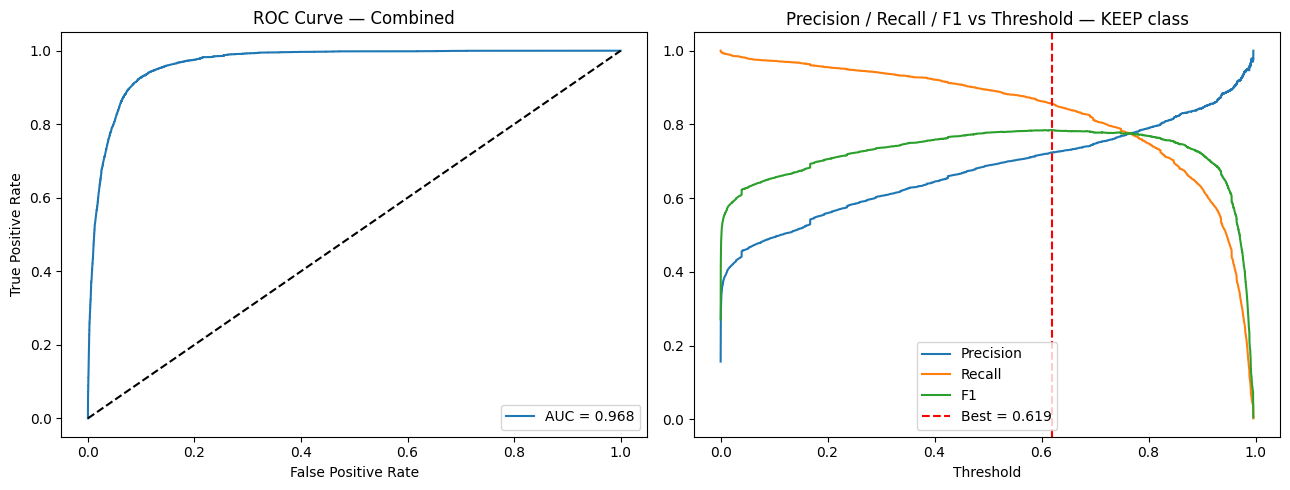


Best threshold: 0.6190  P=0.724  R=0.857  F1=0.785
              precision    recall  f1-score   support

      REMOVE       0.97      0.94      0.96     28340
        KEEP       0.72      0.86      0.78      5267

    accuracy                           0.93     33607
   macro avg       0.85      0.90      0.87     33607
weighted avg       0.93      0.93      0.93     33607



In [22]:
X_train, X_val, y_train, y_val = train_test_split(
    [t for t, l in zip(texts, labels) if l in ("KEEP", "REMOVE")],
    [l for l in labels if l in ("KEEP", "REMOVE")],
    test_size=0.2, random_state=42, stratify=[l for l in labels if l in ("KEEP", "REMOVE")]
)
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

n_remove = y_train.count("REMOVE")
n_keep   = y_train.count("KEEP")
weights  = torch.tensor([1.0, n_remove / n_keep]).cuda()

tokenizer_combined = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

train_ds = QDataset(X_train, y_train)
val_ds   = QDataset(X_val,   y_val)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64)

model_combined = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
model_combined = model_combined.cuda()
optimizer = AdamW(model_combined.parameters(), lr=2e-5)

for epoch in range(3):
    model_combined.train()
    total_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        out = model_combined(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        loss = torch.nn.functional.cross_entropy(out.logits, batch["labels"].cuda(), weight=weights)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}  loss={total_loss/len(train_loader):.4f}")

model_combined.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for batch in val_loader:
        out = model_combined(
            input_ids=batch["input_ids"].cuda(),
            attention_mask=batch["attention_mask"].cuda(),
        )
        probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist()
        all_probs.extend(probs)
        all_true.extend(batch["labels"].tolist())

fpr, tpr, _ = roc_curve(all_true, all_probs)
roc_auc = auc(fpr, tpr)

precision, recall, thresholds = precision_recall_curve(all_true, all_probs)
f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
best_idx = f1_scores.argmax()
best_thresh = thresholds[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve — Combined")
axes[0].legend()

axes[1].plot(thresholds, precision[:-1], label="Precision")
axes[1].plot(thresholds, recall[:-1], label="Recall")
axes[1].plot(thresholds, f1_scores[:-1], label="F1")
axes[1].axvline(best_thresh, color="red", linestyle="--", label=f"Best = {best_thresh:.3f}")
axes[1].set_xlabel("Threshold")
axes[1].set_title("Precision / Recall / F1 vs Threshold — KEEP class")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nBest threshold: {best_thresh:.4f}  P={precision[best_idx]:.3f}  R={recall[best_idx]:.3f}  F1={f1_scores[best_idx]:.3f}")
all_preds = (np.array(all_probs) >= best_thresh).astype(int).tolist()
print(classification_report(all_true, all_preds, target_names=["REMOVE", "KEEP"]))


In [24]:
SAVE_DIR = "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_combined"
os.makedirs(SAVE_DIR, exist_ok=True)

model_combined.save_pretrained(SAVE_DIR)
tokenizer_combined.save_pretrained(SAVE_DIR)

json.dump({"threshold": round(best_thresh, 4)}, open(f"{SAVE_DIR}/config.json", "w"))

print(f"Saved to {SAVE_DIR}")


Writing model shards:   0%|                                                                                                                       | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  4.34it/s]

Saved to /home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_combined


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 104/104 [00:00<00:00, 7931.91it/s]


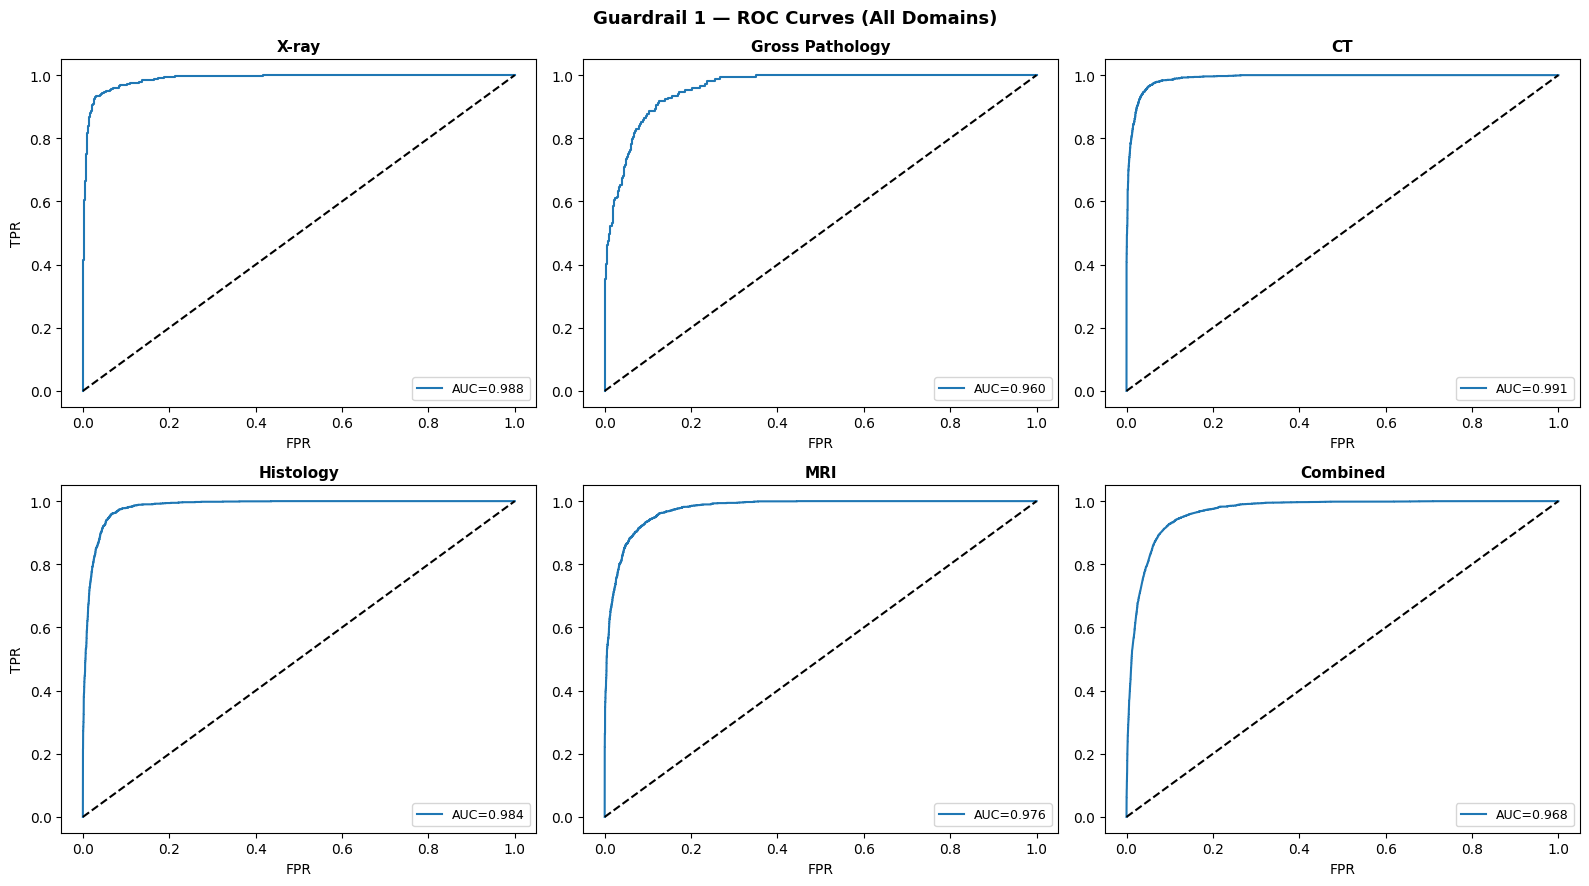

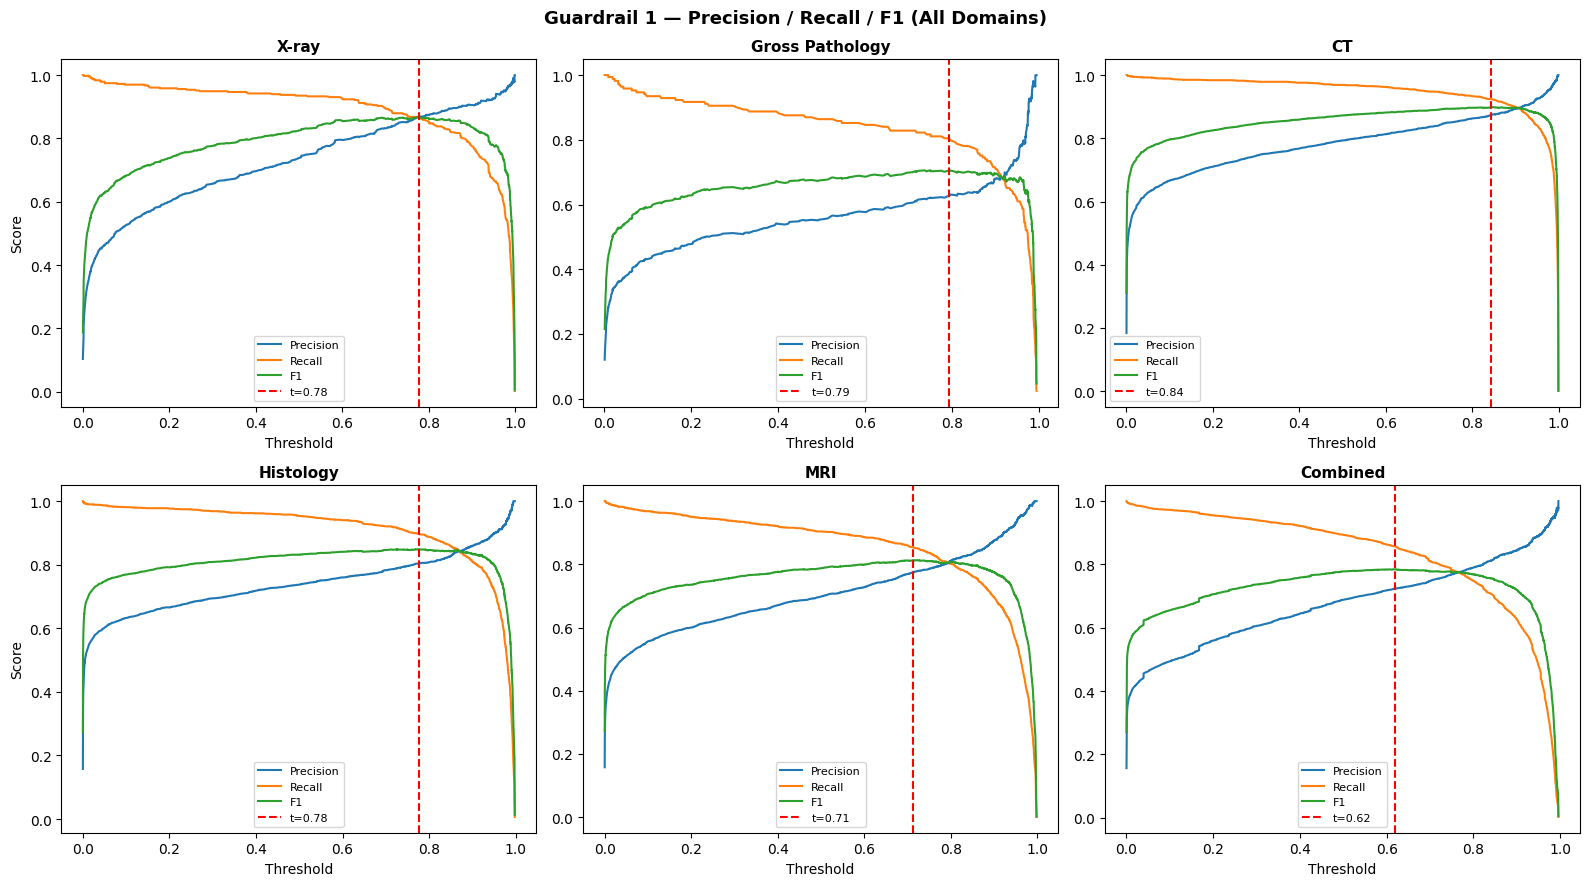

In [25]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt
import torch
import numpy as np
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
from torch.utils.data import DataLoader

DOMAINS = {
    "X-ray":           ("/home/as5606/projects/Super_LlaVA_Med/dataset_3/x_ray/filter_decisions.jsonl",
                        "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_xray"),
    "Gross Pathology": ("/home/as5606/projects/Super_LlaVA_Med/dataset_3/gross_pathology/filter_decisions.jsonl",
                        "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_gross_pathology"),
    "CT":              ("/home/as5606/projects/Super_LlaVA_Med/dataset_3/CT/filter_decisions.jsonl",
                        "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_ct"),
    "Histology":       ("/home/as5606/projects/Super_LlaVA_Med/dataset_3/histology/filter_decisions.jsonl",
                        "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_histology"),
    "MRI":             ("/home/as5606/projects/Super_LlaVA_Med/dataset_3/MRI/filter_decisions.jsonl",
                        "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_mri"),
    "Combined":        ("/home/as5606/projects/Super_LlaVA_Med/dataset_3/combined/filter_decisions.jsonl",
                        "/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail_1_combined"),
}

fig1, axes1 = plt.subplots(2, 3, figsize=(16, 9))
fig2, axes2 = plt.subplots(2, 3, figsize=(16, 9))

for idx, (domain_name, (filter_file, model_dir)) in enumerate(DOMAINS.items()):
    row, col = divmod(idx, 3)

    records = [json.loads(l) for l in open(filter_file)]
    texts  = [r["question"].replace("<image>", "").strip() for r in records if r["decision"] in ("KEEP", "REMOVE")]
    labels = [r["decision"] for r in records if r["decision"] in ("KEEP", "REMOVE")]

    _, X_val, _, y_val = train_test_split(texts, labels, test_size=0.2, random_state=42, stratify=labels)

    mdl = DistilBertForSequenceClassification.from_pretrained(model_dir).cuda().eval()

    val_ds     = QDataset(X_val, y_val)
    val_loader = DataLoader(val_ds, batch_size=64)

    all_probs, all_true = [], []
    with torch.no_grad():
        for batch in val_loader:
            out   = mdl(input_ids=batch["input_ids"].cuda(), attention_mask=batch["attention_mask"].cuda())
            probs = torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist()
            all_probs.extend(probs)
            all_true.extend(batch["labels"].tolist())

    # Figure 1: ROC
    fpr, tpr, _ = roc_curve(all_true, all_probs)
    roc_auc = auc(fpr, tpr)
    axes1[row, col].plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
    axes1[row, col].plot([0, 1], [0, 1], "k--")
    axes1[row, col].set_title(domain_name, fontsize=11, fontweight="bold")
    axes1[row, col].set_xlabel("FPR")
    axes1[row, col].set_ylabel("TPR" if col == 0 else "")
    axes1[row, col].legend(fontsize=9)

    # Figure 2: P/R/F1
    precision, recall, thresholds = precision_recall_curve(all_true, all_probs)
    f1_scores = 2 * precision * recall / (precision + recall + 1e-8)
    best_idx  = f1_scores.argmax()
    best_thresh = thresholds[best_idx]
    axes2[row, col].plot(thresholds, precision[:-1], label="Precision")
    axes2[row, col].plot(thresholds, recall[:-1],    label="Recall")
    axes2[row, col].plot(thresholds, f1_scores[:-1], label="F1")
    axes2[row, col].axvline(best_thresh, color="red", linestyle="--", label=f"t={best_thresh:.2f}")
    axes2[row, col].set_title(domain_name, fontsize=11, fontweight="bold")
    axes2[row, col].set_xlabel("Threshold")
    axes2[row, col].set_ylabel("Score" if col == 0 else "")
    axes2[row, col].legend(fontsize=8)

fig1.suptitle("Guardrail 1 — ROC Curves (All Domains)", fontsize=13, fontweight="bold")
fig1.tight_layout()
fig1.show()

fig2.suptitle("Guardrail 1 — Precision / Recall / F1 (All Domains)", fontsize=13, fontweight="bold")
fig2.tight_layout()
fig2.show()


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 104/104 [00:00<00:00, 6710.68it/s]


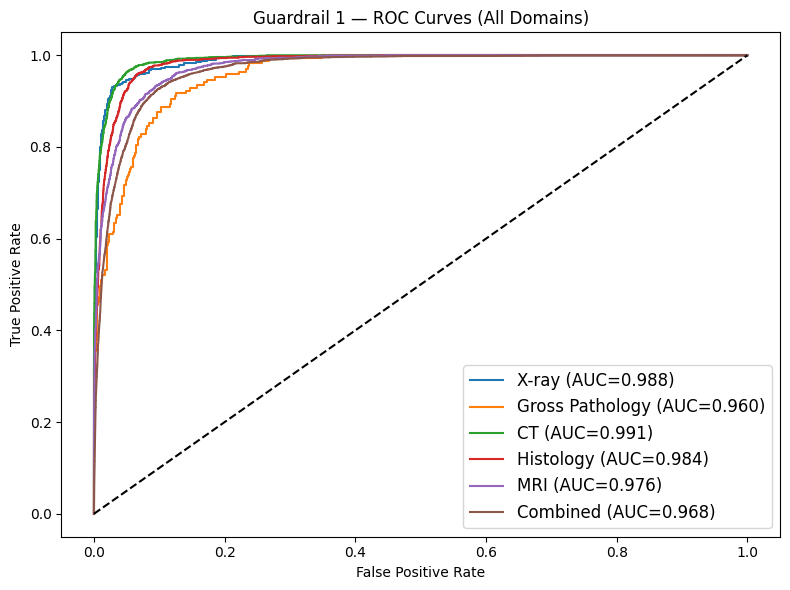

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))

for domain_name, (filter_file, model_dir) in DOMAINS.items():
    records = [json.loads(l) for l in open(filter_file)]
    texts  = [r["question"].replace("<image>", "").strip() for r in records if r["decision"] in ("KEEP", "REMOVE")]
    labels = [r["decision"] for r in records if r["decision"] in ("KEEP", "REMOVE")]

    _, X_val, _, y_val = train_test_split(texts, labels, test_size=0.2, random_state=42, stratify=labels)

    mdl = DistilBertForSequenceClassification.from_pretrained(model_dir).cuda().eval()
    val_loader = DataLoader(QDataset(X_val, y_val), batch_size=64)

    all_probs, all_true = [], []
    with torch.no_grad():
        for batch in val_loader:
            out = mdl(input_ids=batch["input_ids"].cuda(), attention_mask=batch["attention_mask"].cuda())
            all_probs.extend(torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist())
            all_true.extend(batch["labels"].tolist())

    fpr, tpr, _ = roc_curve(all_true, all_probs)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"{domain_name} (AUC={roc_auc:.3f})")

ax.plot([0, 1], [0, 1], "k--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Guardrail 1 — ROC Curves (All Domains)")
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 104/104 [00:00<00:00, 9592.88it/s]


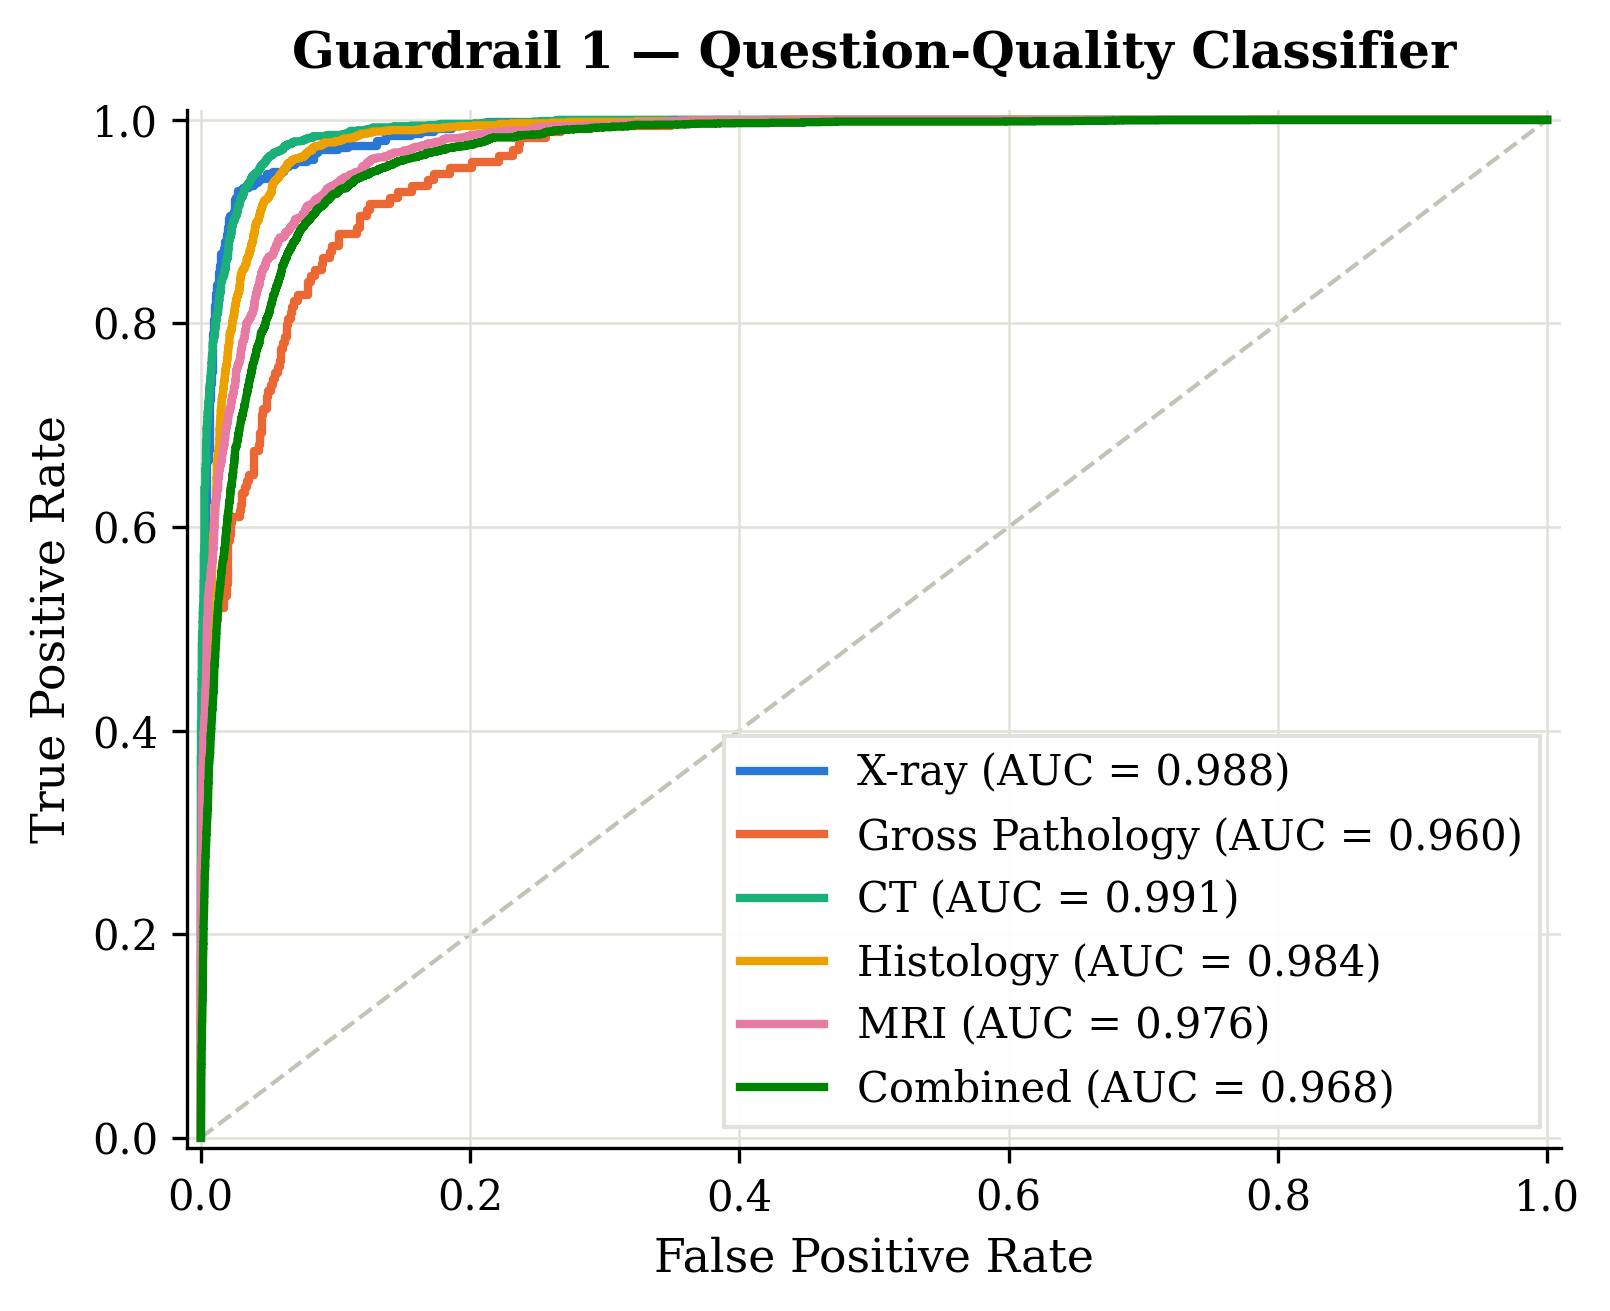

In [28]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# Paper-quality settings
mpl.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Times New Roman", "DejaVu Serif"],
    "font.size":        11,
    "axes.titlesize":   12,
    "axes.labelsize":   11,
    "xtick.labelsize":  10,
    "ytick.labelsize":  10,
    "legend.fontsize":  10,
    "figure.dpi":       300,
    "axes.spines.top":  False,
    "axes.spines.right":False,
    "axes.linewidth":   0.8,
    "xtick.major.width":0.8,
    "ytick.major.width":0.8,
    "lines.linewidth":  2.0,
})

# Validated categorical palette (6 slots, in fixed order)
COLORS = {
    "X-ray":           "#2a78d6",
    "Gross Pathology":  "#eb6834",
    "CT":               "#1baf7a",
    "Histology":        "#eda100",
    "MRI":              "#e87ba4",
    "Combined":         "#008300",
}

fig, ax = plt.subplots(figsize=(5.5, 4.5))

for domain_name, (filter_file, model_dir) in DOMAINS.items():
    records = [json.loads(l) for l in open(filter_file)]
    texts  = [r["question"].replace("<image>", "").strip() for r in records if r["decision"] in ("KEEP", "REMOVE")]
    labels = [r["decision"] for r in records if r["decision"] in ("KEEP", "REMOVE")]

    _, X_val, _, y_val = train_test_split(texts, labels, test_size=0.2, random_state=42, stratify=labels)

    mdl = DistilBertForSequenceClassification.from_pretrained(model_dir).cuda().eval()
    val_loader = DataLoader(QDataset(X_val, y_val), batch_size=64)

    all_probs, all_true = [], []
    with torch.no_grad():
        for batch in val_loader:
            out = mdl(input_ids=batch["input_ids"].cuda(), attention_mask=batch["attention_mask"].cuda())
            all_probs.extend(torch.softmax(out.logits, dim=-1)[:, 1].cpu().tolist())
            all_true.extend(batch["labels"].tolist())

    fpr, tpr, _ = roc_curve(all_true, all_probs)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=COLORS[domain_name], label=f"{domain_name} (AUC = {roc_auc:.3f})")

# Diagonal reference
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1.0, linestyle="--", zorder=0)

# Grid
ax.set_axisbelow(True)
ax.grid(True, color="#e1e0d9", linewidth=0.6, linestyle="-")

ax.set_xlim([-0.01, 1.01])
ax.set_ylim([-0.01, 1.01])
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Guardrail 1 — Question-Quality Classifier", fontweight="bold", pad=10)
ax.legend(loc="lower right", frameon=True, framealpha=0.95,
          edgecolor="#e1e0d9", fancybox=False)

fig.tight_layout()
fig.savefig("guardrail1_roc.pdf", bbox_inches="tight")   # vector for paper
fig.savefig("guardrail1_roc.png", dpi=300, bbox_inches="tight")
plt.show()


In [29]:
fig.savefig("guardrail1_roc.pdf", bbox_inches="tight")
fig.savefig("guardrail1_roc.png", dpi=300, bbox_inches="tight")
plt.show()


In [33]:
fig.savefig("/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail1_roc.pdf", bbox_inches="tight")
fig.savefig("/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail1_roc.png", dpi=300, bbox_inches="tight")



In [34]:
fig2.savefig("/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail1_precision_recall.pdf", bbox_inches="tight")
fig2.savefig("/home/as5606/projects/Super_LlaVA_Med/guardrails/guardrail1_precision_recall.png", dpi=300, bbox_inches="tight")
